# Chapter 74: Contracts, Liability, Legal Rules, and Enforcement

This notebook reruns four worked examples from the chapter: strict liability against negligence, expectation damages and efficient breach, deterrence through detection and severity, and the price premium created by prohibition. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def liability_activity(a, care_cost, harm, rule, low_care=(2.0, 9.0)):
    """Activity level z with benefit B(z) = a z - z^2/2 under strict liability or negligence.

    care_cost and harm are the due-care values; low_care = (cost, harm) is the alternative.
    Under strict liability the firm bears cost plus harm and picks the cheaper care; under negligence
    (due care set correctly) it complies when care_cost <= low-care private cost plus damages and then
    bears only care_cost. Principle: strict-liability-versus-negligence-result. Book (ch074): a = 24,
    low care 2 + 9 = 11, due care 5 + 3 = 8; z = 16 under strict liability, 19 under negligence.
    """
    lc, lh = low_care
    social_low, social_due = lc + lh, care_cost + harm
    efficient_care = "due" if social_due <= social_low else "low"
    social_unit = min(social_due, social_low)
    if rule == "strict":
        care = "due" if social_due <= social_low else "low"
        private_unit = social_due if care == "due" else social_low
    else:
        care = "due" if care_cost <= social_low else "low"
        private_unit = care_cost if care == "due" else social_low
    z = max(0.0, a - private_unit)
    z_eff = max(0.0, a - social_unit)
    social_of_choice = social_due if care == "due" else social_low

    def surplus(zz, unit):
        return a * zz - zz * zz / 2 - unit * zz

    excess = surplus(z_eff, social_unit) - surplus(z, social_of_choice)
    return {"social_low": social_low, "social_due": social_due, "efficient_care": efficient_care, "care": care,
            "private_unit": private_unit, "z": z, "z_eff": z_eff, "excess_units": z - z_eff,
            "deadweight": excess, "expected_harm": z * (harm if care == "due" else lh)}


def breach_decision(P, V, C, D):
    """Seller performs (payoff P - C) or breaches and pays damages (payoff -D).

    Performance is efficient when V > C. Principle: expectation-damages-efficient-performance-result.
    Book (ch074): P = 80, V = 125, D = 125 - 80 = 45; C = 100: perform -20 beats breach -45, surplus 25;
    C = 150: perform -70, breach; D = 15 at C = 100 breaches (-15 > -20); D = 80 at C = 150 performs.
    """
    perform, breach = P - C, -D
    tie = abs(perform - breach) < 1e-9
    performs = perform > breach
    efficient_perform = V > C
    return {"perform_payoff": perform, "breach_payoff": breach, "tie": tie, "performs": performs,
            "efficient_perform": efficient_perform, "social_gap": abs(V - C),
            "efficient": tie or V == C or performs == efficient_perform, "expectation": V - P}


def becker_payoff(gain, moral, p, F, collect=1.0):
    """Net payoff of an offence: gain - moral - p (collect F).

    Principle: becker-deterrence-model-of-crime. Book (ch074): 40 - 6 - 0.08(150) = 22;
    p = 0.25: -3.5; F = 470: -3.6; collect 0.40: 0.40 x 470 = 188 and 40 - 6 - 0.08(188) = 18.96.
    """
    effective = collect * F
    sanction = p * effective
    net = gain - moral - sanction
    return {"effective_penalty": effective, "expected_sanction": sanction, "net": net, "offends": net > 0,
            "tie": abs(net) < 1e-9}


def uniform_share_above(lo, hi, threshold, n=1.0):
    """Expected number (n times the share) of a uniform [lo, hi] population above threshold.

    Principle: becker-deterrence-model-of-crime. Book (ch074): 1,000 riders uniform on 0 to 60;
    a sanction of 12 leaves 800 with positive returns and 36 leaves 400.
    """
    share = min(1.0, max(0.0, (hi - threshold) / (hi - lo)))
    return n * share


def prohibition_price(cost, conceal, punish, seize):
    """Break-even delivered price (cost + conceal + punish) / (1 - seize).

    Principle: prohibition-risk-premium. Book (ch074): (45 + 7 + 8)/0.80 = 75; (45 + 25 + 14)/0.70 = 120;
    (81 + 7 + 8)/0.80 = 120.
    """
    return (cost + conceal + punish) / (1 - seize)


def linear_demand_quantity(a, b, p):
    """Q = a - b p, floored at zero."""
    return max(0.0, a - b * p)


plt.rcParams.update(HOUSE_RC)


public = SimpleNamespace(liability_activity=liability_activity, breach_decision=breach_decision, becker_payoff=becker_payoff, uniform_share_above=uniform_share_above, prohibition_price=prohibition_price)


choice = SimpleNamespace(linear_demand_quantity=linear_demand_quantity)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'strict-liability-versus-negligence-result': {'a': 24,
                                               'low_cost': 2,
                                               'low_harm': 9,
                                               'due_cost': 5,
                                               'due_harm': 3,
                                               'social_low': 11,
                                               'social_due': 8,
                                               'z_strict': 16,
                                               'z_negligence': 19},
 'expectation-damages-efficient-performance-result': {'P': 80,
                                                      'V': 125,
                                                      'D': 45,
                                                      'C': 100,
                                                      'perform': -20,
                                                      'surplus': 25,
                                                      'C_2': 150,
                                                      'perform_2': -70,
                                                      'D_low': 15,
                                                      'D_high': 80,
                                                      'resale': 160,
                                                      'resale_net': 115},
 'becker-deterrence-model-of-crime': {'gain': 40,
                                      'moral': 6,
                                      'F': 150,
                                      'p': 0.08,
                                      'net': 22,
                                      'p_2': 0.25,
                                      'net_2': -3.5,
                                      'F_2': 470,
                                      'net_3': -3.6,
                                      'collect': 0.4,
                                      'effective': 188,
                                      'net_4': 18.96,
                                      'riders': 1000,
                                      'hi': 60,
                                      'evading_12': 800,
                                      'evading_36': 400},
 'prohibition-risk-premium': {'cost': 45,
                              'conceal': 7,
                              'punish': 8,
                              'seize': 0.2,
                              'p_L': 75,
                              'Q_L': 1050,
                              'conceal_H': 25,
                              'punish_H': 14,
                              'seize_H': 0.3,
                              'p_H': 120,
                              'Q_H': 600,
                              'cost_2': 81,
                              'p_2': 120},
 'constructed': {'strict-liability-versus-negligence-result': {'due_harm': [1, 5]},
                 'expectation-damages-efficient-performance-result': {'C': [125]},
                 'becker-deterrence-model-of-crime': {'p': [0.15]},
                 'prohibition-risk-premium': {'cost': [63]}}}


def nz(x):
    """Whole numbers without decimals, others with two: 1050 -> '1,050', 342.857 -> '342.86'."""
    return num(x, 0) if abs(x - round(x)) < 1e-9 else num(x, 2)


def liability_picture(rule="strict", h=3):
    bv = BV["strict-liability-versus-negligence-result"]
    a, dc = bv["a"], bv["due_cost"]
    r = public.liability_activity(a, dc, h, rule, (bv["low_cost"], bv["low_harm"]))
    z, ze = r["z"], r["z_eff"]
    social = r["social_due"]
    fig, ax = new_figure()
    zs = np.linspace(0, 24, 200)
    ax.plot(zs, a - zs, color=PALETTE["navy"], linewidth=2.2, label="marginal benefit 24 - z")
    ax.axhline(social, color=PALETTE["terracotta"], linewidth=1.8, label=f"full social cost {num(social, 0)}")
    if abs(r["private_unit"] - social) > 1e-9:
        ax.axhline(r["private_unit"], color=PALETTE["teal"], linestyle="dashed", linewidth=1.8,
                   label=f"firm's own cost {num(r['private_unit'], 0)}")
    if z > ze:
        ax.fill([ze, z, z], [social, social, a - z], color=PALETTE["terracotta"], alpha=0.35)
    mark(ax, z, a - z, f"firm chooses z = {num(z, 0)}", col="ink", dx=-8, dy=-8, ha="right", va="top")
    if z > ze:
        mark(ax, ze, a - ze, f"efficient z = {num(ze, 0)}", col="terracotta", dx=8, dy=8)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlim(0, 24)
    ax.set_ylim(0, 26)
    ax.set_xlabel("Route units z")
    ax.set_ylabel("Value per route unit")
    rule_name = "strict liability" if rule == "strict" else "negligence"
    metrics = {"Social cost per unit, low care": num(r["social_low"], 0),
               "Social cost per unit, due care": num(social, 0),
               "Care chosen": "Due care" if r["care"] == "due" else "Low care",
               "Firm's cost per unit": num(r["private_unit"], 0), "Route units z": num(z, 0),
               "Efficient units": num(ze, 0), "Excess units": num(z - ze, 0),
               "Lost surplus (red triangle)": num(r["deadweight"], 2)}
    steps = [f"Social cost per unit: low care 2 + 9 = {num(r['social_low'], 0)}, due care 5 + {h} = {num(social, 0)}"]
    if rule == "strict":
        steps += [f"Strict liability: the firm bears 5 + {h} = {num(social, 0)} per unit and picks due care",
                  f"24 - z - {num(social, 0)} = 0 gives z = {num(z, 0)}"]
        verdict = (f"The firm pays for the harm, so it faces the full social cost {num(social, 0)} and chooses "
                   f"z = 24 - {num(social, 0)} = {num(z, 0)}, the efficient level.")
    else:
        steps += ["Negligence: noncompliance costs 2 + 9 = 11, compliance costs 5, so the firm takes due care",
                  f"Once compliant it owes no damages: 24 - z - 5 = 0 gives z = {num(z, 0)}",
                  f"Excess units = {num(z, 0)} - {num(ze, 0)} = {num(z - ze, 0)}; lost surplus = 0.5 x "
                  f"{num(z - ze, 0)} x {num(z - ze, 0)} = {num(r['deadweight'], 2)}"]
        verdict = (f"A compliant firm bears only the care cost 5, not the expected harm {h}, so it chooses "
                   f"z = 24 - 5 = {num(z, 0)}, {num(z - ze, 0)} more than the efficient {num(ze, 0)}. Those extra "
                   f"units have marginal benefit below the full social cost {num(social, 0)}.")
    why = (f"since 5 + {h} = {num(social, 0)} is below 2 + 9 = 11" if rule == "strict"
           else "since compliance costs 5, below the 2 + 9 = 11 it would bear if negligent")
    interp = (f"Under {rule_name} the firm takes due care, {why}. "
              f"{verdict} Both rules get care right; only strict liability also gets the activity level right.")
    alt = (f"Marginal benefit 24 - z against the full social cost {num(social, 0)}"
           + ("" if rule == "strict" else " and the firm's own cost 5")
           + f". Under {rule_name} the firm chooses {num(z, 0)} route units; the efficient level is {num(ze, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def breach_picture(cost=100, damages=45):
    bv = BV["expectation-damages-efficient-performance-result"]
    P, V = bv["P"], bv["V"]
    r = public.breach_decision(P, V, cost, damages)
    fig, ax = new_figure()
    vals = [r["perform_payoff"], r["breach_payoff"]]
    if r["tie"]:
        cols = [PALETTE["gold"], PALETTE["gold"]]
    else:
        cols = [PALETTE["teal"] if r["performs"] else PALETTE["light"],
                PALETTE["light"] if r["performs"] else PALETTE["teal"]]
    ax.bar([0, 1], vals, color=cols, width=0.5)
    for x, v in enumerate(vals):
        ax.annotate(num(v, 0), (x, v), xytext=(0, -4), textcoords="offset points", ha="center", va="top",
                    fontsize=10.5, color=PALETTE["ink"])
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks([0, 1], [f"perform: {P} - {cost}", f"breach: pay {damages}"])
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(-105, 30)
    ax.set_xlabel("Shop's option (chosen option in teal)")
    ax.set_ylabel("Shop's payoff")
    if V > cost:
        social = f"Society: perform (value {V} > cost {cost})"
        eff_text = "perform"
    elif V < cost:
        social = f"Society: breach (cost {cost} > value {V})"
        eff_text = "breach"
    else:
        social = f"Society: indifferent (value {V} = cost {cost})"
        eff_text = "either"
    ax.text(0.98, 0.95, social, transform=ax.transAxes, ha="right", va="top", fontsize=10.5,
            color=PALETTE["terracotta"])
    if r["tie"]:
        shop = "Indifferent (tie)"
    else:
        shop = "Perform" if r["performs"] else "Breach"
    lost = 0.0 if r["efficient"] else r["social_gap"]
    metrics = {"Expectation damages V - P": num(V - P, 0), "Payoff from performing": num(r["perform_payoff"], 0),
               "Payoff from breaching": num(r["breach_payoff"], 0), "Shop's choice": shop,
               "Efficient choice": eff_text.capitalize(), "Social value lost": num(lost, 0)}
    steps = [f"Expectation damages = {V} - {P} = {V - P}; damages awarded = {damages}",
             f"Perform: {P} - {cost} = {num(r['perform_payoff'], 0)}; breach: -{damages}",
             f"Social comparison: value {V} against cost {cost}, difference {num(V - cost, 0)}"]
    if r["tie"]:
        verdict = "The shop is indifferent between performing and breaching."
    elif r["performs"]:
        verdict = (f"Since {num(r['perform_payoff'], 0)} > {num(-damages, 0)}, the shop performs.")
    else:
        verdict = (f"Since {num(-damages, 0)} > {num(r['perform_payoff'], 0)}, the shop breaches and pays "
                   f"{damages}.")
    if r["tie"] or V == cost:
        social_line = "Society gains or loses nothing either way."
    elif r["efficient"]:
        social_line = (f"That matches the efficient choice: {abs(V - cost)} of social value is "
                       f"{'created' if V > cost else 'saved'}.")
    else:
        social_line = (f"That is inefficient: it {'destroys' if V > cost else 'wastes'} {abs(V - cost)} of social "
                       f"value, because damages of {damages} differ from the true expectation {V - P}.")
    interp = (f"Performing pays {P} - {cost} = {num(r['perform_payoff'], 0)}; breaching costs the damages "
              f"{damages}. {verdict} {social_line}")
    alt = (f"Shop payoffs: performing {num(r['perform_payoff'], 0)} and breaching {signed(-damages, 0)}. The shop's "
           f"choice is {shop.lower()}; the efficient choice is {eff_text}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def deterrence_picture(p=0.08, fine=150, collect=1.00):
    bv = BV["becker-deterrence-model-of-crime"]
    gain, moral, n, hi = bv["gain"], bv["moral"], bv["riders"], bv["hi"]
    r = public.becker_payoff(gain, moral, p, fine, collect)
    s = r["expected_sanction"]
    riders = public.uniform_share_above(0, hi, s, n)
    fig, (ax, ax2) = new_figure(2)
    names = ["gain", "moral cost", "expected sanction", "net payoff"]
    vals = [gain, -moral, -s, r["net"]]
    cols = [PALETTE["teal"], PALETTE["grey"], PALETTE["navy"],
            PALETTE["terracotta"] if r["net"] > 0 else PALETTE["olive"]]
    ax.barh(range(4), vals, color=cols, height=0.55)
    for y, v in enumerate(vals):
        ax.annotate(num(v, 2), (v, y), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points",
                    ha="left" if v >= 0 else "right", va="center", fontsize=10.5, color=PALETTE["ink"])
    ax.axvline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_yticks(range(4), names)
    ax.invert_yaxis()
    ax.set_xlim(-160, 75)
    ax.set_xlabel("One rider's monthly payoff")
    ax.set_ylabel("Payoff part")
    xs = np.linspace(0, hi, 200)
    ax2.fill_between(xs, 0, n / hi, color=PALETTE["light"])
    if s < hi:
        ax2.fill_between(np.linspace(s, hi, 100), 0, n / hi, color=PALETTE["terracotta"], alpha=0.75)
    if s <= hi:
        ax2.axvline(s, color=PALETTE["navy"], linestyle="dashed", linewidth=1.4)
    ax2.text(0.03, 0.95, f"red: {num(riders, 1)} of {num(n, 0)} riders evade", transform=ax2.transAxes,
             ha="left", va="top", fontsize=10.5, color=PALETTE["terracotta"], zorder=6,
             bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.95})
    ax2.set_xlim(0, hi + 2)
    ax2.set_ylim(0, 1.6 * n / hi)
    ax2.set_xlabel(f"Net benefit before sanction (sanction {num(s, 2)})")
    ax2.set_ylabel("Riders per unit of benefit")
    metrics = {"Effective penalty": nz(r["effective_penalty"]), "Expected sanction": num(s, 2),
               "Net payoff": num(r["net"], 2), "This rider": "Evades" if r["net"] > 0 else (
                   "Indifferent" if r["tie"] else "Does not evade"),
               "Expected riders evading (of 1,000)": num(riders, 1)}
    steps = [f"Effective penalty = {num(collect)} x {fine} = {nz(r['effective_penalty'])}",
             f"Expected sanction = {num(p)} x {nz(r['effective_penalty'])} = {num(s, 2)}",
             f"Net payoff = 40 - 6 - {num(s, 2)} = {num(r['net'], 2)}"]
    if s < hi:
        steps.append(f"Riders evading = 1,000 x (60 - {num(s, 2)}) / 60 = {num(riders, 1)}")
    else:
        steps.append(f"The sanction {num(s, 2)} exceeds every rider's benefit of at most 60, so no rider evades")
    crowd = (f"about {num(riders, 1)} still evade" if s < hi
             else f"none still evade, since the sanction {num(s, 2)} exceeds the largest benefit of 60")
    if r["net"] > 0:
        verdict = "positive, so this rider keeps evading"
    elif r["tie"]:
        verdict = "zero, so this rider is indifferent"
    else:
        verdict = "negative, so this rider stops evading"
    interp = (f"With detection {num(p)}, a stated penalty of {fine} and {num(100 * collect, 0)} percent collected, "
              f"the expected sanction is {num(p)} x {nz(r['effective_penalty'])} = {num(s, 2)}. The net payoff "
              f"40 - 6 - {num(s, 2)} = {num(r['net'], 2)} is {verdict}. Across 1,000 riders with benefits spread "
              f"evenly from 0 to 60, {crowd}. A stated penalty deters only to the extent "
              f"it is detected and collected.")
    alt = (f"Left: gain 40, moral cost 6 and expected sanction {num(s, 2)} give a net payoff of {num(r['net'], 2)}. "
           f"Right: a uniform spread of 1,000 riders' benefits from 0 to 60, with {num(riders, 1)} above the "
           f"sanction.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


REGIMES = {"low": (0.20, 7, 8), "high": (0.30, 25, 14)}


def prohibition_picture(enf="low", cost=45):
    seize, conceal, punish = REGIMES[enf]
    price = public.prohibition_price(cost, conceal, punish, seize)
    q = choice.linear_demand_quantity(1_800, 10, price)
    fig, ax = new_figure()
    qs = np.linspace(0, 1_800, 200)
    ax.plot(qs, (1_800 - qs) / 10, color=PALETTE["navy"], linewidth=2.2, label="demand Q = 1,800 - 10p")
    ax.axhline(price, color=PALETTE["terracotta"], linewidth=1.8, label=f"break-even price {nz(price)}")
    mark(ax, q, price, f"Q = {nz(q)}", col="ink", dx=8, dy=8)
    ax.legend(loc="lower left", frameon=False)
    ax.set_xlim(0, 1_900)
    ax.set_ylim(0, 195)
    ax.set_xlabel("Quantity")
    ax.set_ylabel("Delivered price p")
    regime = "low" if enf == "low" else "high"
    total = cost + conceal + punish
    metrics = {"Seizure probability": num(seize), "Cost per attempt": num(total, 0),
               "Break-even price": nz(price), "Quantity": nz(q)}
    steps = [f"Cost per attempt = {cost} + {conceal} + {punish} = {total}",
             f"p = {total} / {num(1 - seize)} = {nz(price)}",
             f"Q = 1,800 - 10 x {nz(price) if abs(price - round(price, 2)) < 1e-9 else num(price, 4)} = {nz(q)}"]
    same = ""
    if abs(price - 120) < 1e-9:
        same = (" The same price of 120 arises from low enforcement with cost 81 and from high enforcement with "
                "cost 45, so the price alone cannot reveal the enforcement channel.")
    interp = (f"Under {regime} enforcement a supplier pays {cost} + {conceal} + {punish} = {total} per attempt and "
              f"loses a share {num(seize)} of shipments, so the break-even price is {total} / {num(1 - seize)} = "
              f"{nz(price)} and buyers take {nz(q)}.{same}")
    alt = (f"Demand line Q = 1,800 - 10p with a horizontal break-even price of {nz(price)} under {regime} "
           f"enforcement and production cost {cost}; quantity {nz(q)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Strict liability versus negligence: care and activity level

The firm's benefit is

$$B(z)=24z-\frac{z^2}{2}$$

Due care costs 5 and leaves harm 3. Under strict liability the condition is $24-z-8=0$; under negligence a compliant firm solves $24-z-5=0$.

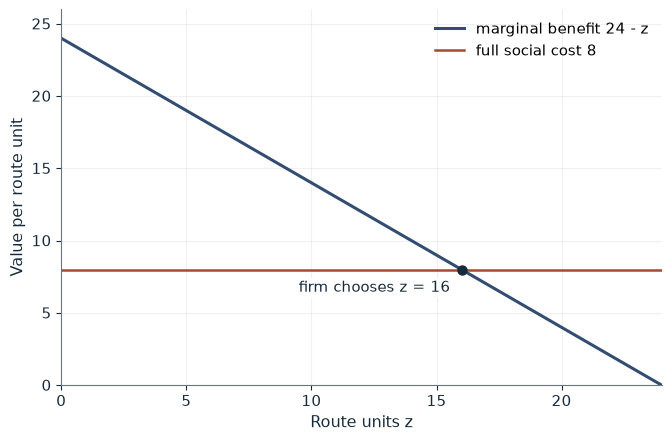

Social cost per unit, low care  11
Social cost per unit, due care  8
Care chosen                     Due care
Firm's cost per unit            8
Route units z                   16
Efficient units                 16
Excess units                    0
Lost surplus (red triangle)     0.00

Worked steps:
  1. Social cost per unit: low care 2 + 9 = 11, due care 5 + 3 = 8
  2. Strict liability: the firm bears 5 + 3 = 8 per unit and picks due care
  3. 24 - z - 8 = 0 gives z = 16

Under strict liability the firm takes due care, since 5 + 3 = 8 is below 2 + 9 = 11. The firm pays for the harm, so it faces the full social cost 8 and chooses z = 24 - 8 = 16, the efficient level. Both rules get care right; only strict liability also gets the activity level right.


In [2]:
show(liability_picture(rule='strict', h=3))

Change one input, `rule`, and hold the others at the book's values:

In [3]:
sweep(liability_picture, 'rule', ['strict', 'negligence'], {'h': 3}, ['Care chosen', 'Route units z', 'Excess units'])

rule | Care chosen | Route units z | Excess units
strict | Due care | 16 | 0
negligence | Due care | 19 | 3


Both rules induce due care, but negligence gives 19 route units against the efficient 16, because a compliant firm does not bear the residual harm.

## 2. Expectation damages: efficient breach

Price 80, buyer value 125.

$$D=125-80=45$$

At cost 100 performing pays $80-100=-20$, better than paying 45, and creates $125-100=25$.

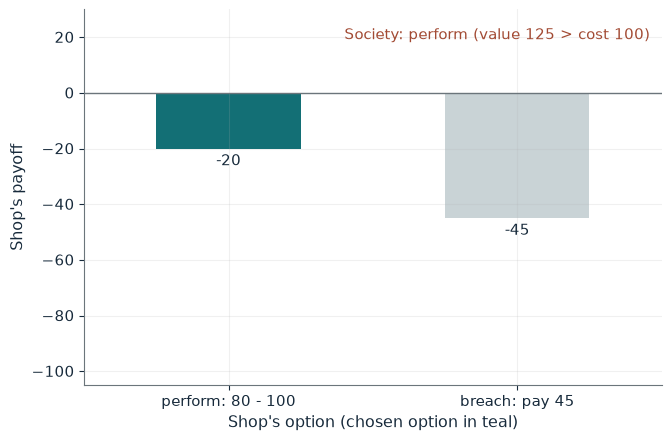

Expectation damages V - P  45
Payoff from performing     -20
Payoff from breaching      -45
Shop's choice              Perform
Efficient choice           Perform
Social value lost          0

Worked steps:
  1. Expectation damages = 125 - 80 = 45; damages awarded = 45
  2. Perform: 80 - 100 = -20; breach: -45
  3. Social comparison: value 125 against cost 100, difference 25

Performing pays 80 - 100 = -20; breaching costs the damages 45. Since -20 > -45, the shop performs. That matches the efficient choice: 25 of social value is created.


In [4]:
show(breach_picture(cost=100, damages=45))

Change one input, `damages`, and hold the others at the book's values:

In [5]:
sweep(breach_picture, 'damages', [15, 45, 80], {'cost': 100}, ["Shop's choice", 'Efficient choice', 'Social value lost'])

damages | Shop's choice | Efficient choice | Social value lost
15 | Breach | Perform | 25
45 | Perform | Perform | 0
80 | Perform | Perform | 0


Correct damages make the shop perform exactly when value exceeds cost. Damages of 15 at cost 100 invite a breach that destroys 25; damages of 80 at cost 150 force a performance that wastes 25.

## 3. Becker deterrence: probability against severity

A rider gains 40 and bears moral cost 6.

$$40-6-(0.08)(150)=22, \qquad 40-6-(0.25)(150)=-3.5$$

With 40 percent collection of a 470 penalty, $0.40\times470=188$ and

$$40-6-(0.08)(188)=18.96$$

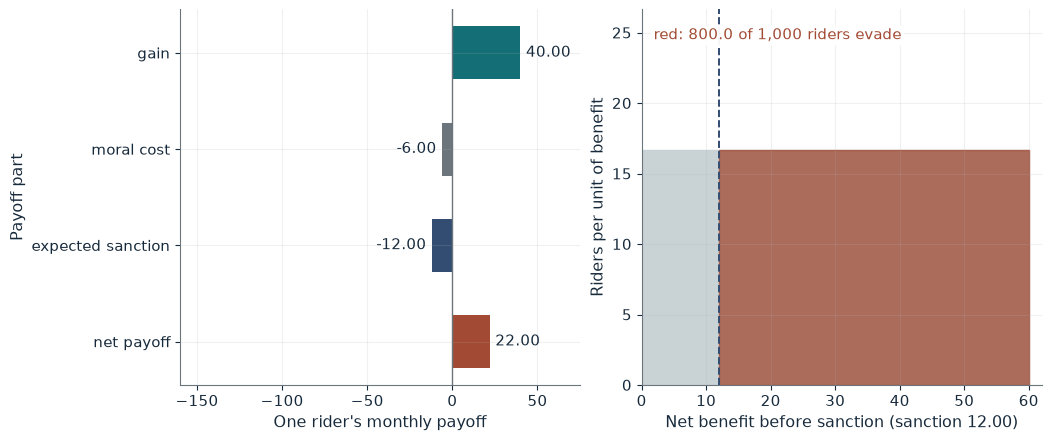

Effective penalty                   150
Expected sanction                   12.00
Net payoff                          22.00
This rider                          Evades
Expected riders evading (of 1,000)  800.0

Worked steps:
  1. Effective penalty = 1.00 x 150 = 150
  2. Expected sanction = 0.08 x 150 = 12.00
  3. Net payoff = 40 - 6 - 12.00 = 22.00
  4. Riders evading = 1,000 x (60 - 12.00) / 60 = 800.0

With detection 0.08, a stated penalty of 150 and 100 percent collected, the expected sanction is 0.08 x 150 = 12.00. The net payoff 40 - 6 - 12.00 = 22.00 is positive, so this rider keeps evading. Across 1,000 riders with benefits spread evenly from 0 to 60, about 800.0 still evade. A stated penalty deters only to the extent it is detected and collected.


In [6]:
show(deterrence_picture(p=0.08, fine=150, collect=1.00))

Change one input, `p`, and hold the others at the book's values:

In [7]:
sweep(deterrence_picture, 'p', [0.08, 0.15, 0.25], {'fine': 150, 'collect': 1.0}, ['Expected sanction', 'Net payoff', 'Expected riders evading (of 1,000)'])

p | Expected sanction | Net payoff | Expected riders evading (of 1,000)
0.08 | 12.00 | 22.00 | 800.0
0.15 | 22.50 | 11.50 | 625.0
0.25 | 37.50 | -3.50 | 375.0


Raising detection to 25 percent turns the payoff negative. A larger stated penalty deters only to the extent it is collected: at 40 percent collection the 470 penalty leaves a payoff of 18.96.

## 4. Prohibition risk premium

$$p_L=\frac{45+7+8}{0.80}=75, \qquad p_H=\frac{45+25+14}{0.70}=120$$

Demand is $Q_D=1{,}800-10p$.

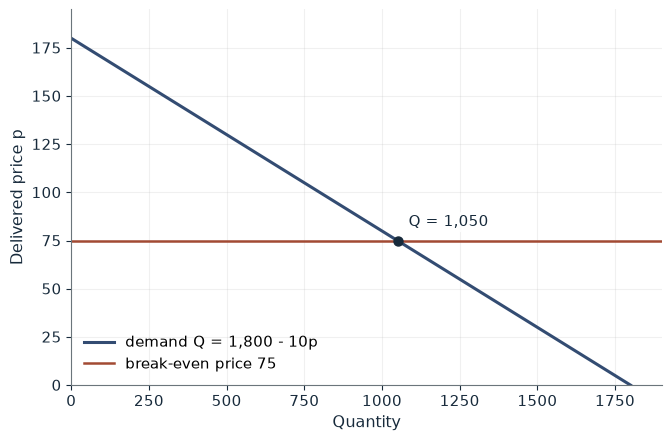

Seizure probability  0.20
Cost per attempt     60
Break-even price     75
Quantity             1,050

Worked steps:
  1. Cost per attempt = 45 + 7 + 8 = 60
  2. p = 60 / 0.80 = 75
  3. Q = 1,800 - 10 x 75 = 1,050

Under low enforcement a supplier pays 45 + 7 + 8 = 60 per attempt and loses a share 0.20 of shipments, so the break-even price is 60 / 0.80 = 75 and buyers take 1,050.


In [8]:
show(prohibition_picture(enf='low', cost=45))

Change one input, `cost`, and hold the others at the book's values:

In [9]:
sweep(prohibition_picture, 'cost', [45, 63, 81], {'enf': 'low'}, ['Break-even price', 'Quantity'])

cost | Break-even price | Quantity
45 | 75 | 1,050
63 | 97.50 | 825
81 | 120 | 600


Low enforcement gives price 75 and quantity 1,050; high enforcement gives 120 and 600. Low enforcement with production cost 81 also gives 120, so the price alone cannot identify the enforcement channel.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

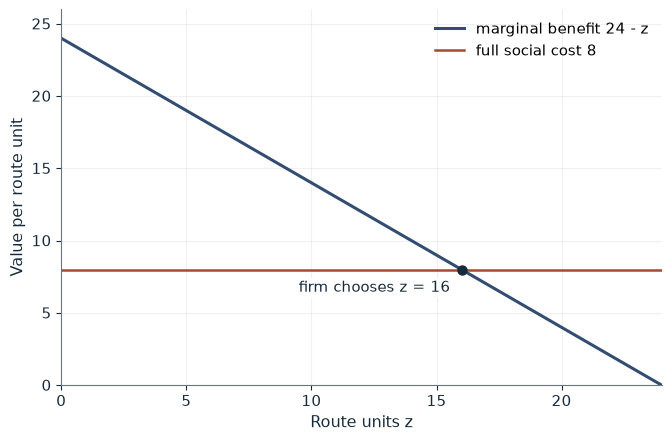

Social cost per unit, low care  11
Social cost per unit, due care  8
Care chosen                     Due care
Firm's cost per unit            8
Route units z                   16
Efficient units                 16
Excess units                    0
Lost surplus (red triangle)     0.00

Worked steps:
  1. Social cost per unit: low care 2 + 9 = 11, due care 5 + 3 = 8
  2. Strict liability: the firm bears 5 + 3 = 8 per unit and picks due care
  3. 24 - z - 8 = 0 gives z = 16

Under strict liability the firm takes due care, since 5 + 3 = 8 is below 2 + 9 = 11. The firm pays for the harm, so it faces the full social cost 8 and chooses z = 24 - 8 = 16, the efficient level. Both rules get care right; only strict liability also gets the activity level right.


In [10]:
show(liability_picture(rule='strict', h=3))

## Practice

**1.** Under negligence, what is z, and why is it too high?

<details><summary>Answer</summary>

24 - z - 5 = 0 gives z = 19; units 17 to 19 are worth less than the full social cost 8.

</details>

**2.** At cost 150 and damages 80, does the shop perform, and is that efficient?

<details><summary>Answer</summary>

80 - 150 = -70 beats -80, so it performs, wasting 150 - 125 = 25.

</details>

**3.** Under low enforcement with production cost 81, what is the price?

<details><summary>Answer</summary>

(81 + 7 + 8) / 0.80 = 96 / 0.80 = 120, with quantity 600.

</details>